# **LAB Deep Learning - Session 9 (GAN)**

## **Import Library**

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import load_img, img_to_array

## **Settings/Global Variable**

In [2]:
IMAGE_FOLDER = "./sign_mnist"
BATCH_SIZE = 32
EPOCHS = 5
NOISE_DIM = 100 # karena GAN ambil noise secara acak dari dataset, kasih batasan noise nya

seed = tf.random.normal([16, NOISE_DIM]) # 16 gambar noise random, noise nya itu2 aja, setelah 16 noisenya akan random

## **Ambil Dataset**

In [3]:
images = []

for split in ["train", "test"]:
    split_path = os.path.join(IMAGE_FOLDER, split) # masuk folder train atau test
    for kelas in os.listdir(split_path):
        kelas_path = os.path.join(split_path, kelas) # masuk folder kelas
        # masuk ke class folder(0, 1, 2, .. 24)
        for nama_file in os.listdir(kelas_path):
            img = load_img(os.path.join(kelas_path, nama_file), target_size=(28, 28), color_mode="grayscale") # load gambar. target size dari properties gambar details nya 28x28

            images.append(img_to_array(img)) # ubah gambar ke array, karena gambar itu 2D, jadi array nya 2D juga

images = np.array(images, dtype="float32") # ubah list images ke array, biar bisa diolah pake numpy

# di GAN gabisa langsung bagi ke 255. jadi -1 / 1. kalo langsung bagi ke 255, jadi semuanya true. diskriminator perlu nilai negatif. makanya pake rumus dibawah ini:
images = (images - 127.5) / 127.5 # ubah range pixel dari 0-255 ke -1 sampai 1
print("Jumlah gambar:", images.shape)

dataset = tf.data.Dataset.from_tensor_slices(images).shuffle(len(images)).batch(BATCH_SIZE) # shuffle biar random, buffer size 1024 biar randomnya lebih bagus, batch size 32 biar bisa diolah per batch

Jumlah gambar: (34627, 28, 28, 1)


## **Generator Model**

In [9]:
def make_generator_model(): # perbesar image
    return tf.keras.Sequential([
        layers.Dense(7*7*256, use_bias=False, input_shape=(NOISE_DIM,)), # layers 12.000 an ini
        layers.BatchNormalization(), # biar lebih stabil, biar ga terlalu random
        layers.LeakyReLU(), # biar ga terlalu random, biar lebih stabil
        layers.Reshape((7, 7, 256)), # ubah ke 7x7x256

        layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False), #128 perceptron
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False), #128 perceptron
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")
    ])

generator = make_generator_model()
generator.summary()

c:\SEM 5\LAB AI Semester 5\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## **Model Discriminator**

In [10]:
def make_discriminator(): # kecilin image
    return tf.keras.Sequential([
        layers.Conv2D(64, 5, strides=2, padding="same", input_shape=(28, 28, 1)), # 64 perceptron
        layers.LeakyReLU(),
        layers.Dropout(0.3), # biar ga terlalu random

        layers.Conv2D(128, 5, strides=2, padding="same"), # 128 perceptron
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(), # ubah ke 1D
        layers.Dense(1) # outputnya 1
    ])

discriminator = make_discriminator()
discriminator.summary()

c:\SEM 5\LAB AI Semester 5\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## **Loss Function dan Optimizer**

In [11]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True) # loss function biar bisa dioptimasi

def discriminator_loss(real_output, fake_output): # loss function untuk diskriminator
    # real loss = yang harusnya asli ditebak palsu
    # fake loss = yang harusnya palsu ditebak asli
    real_loss = cross_entropy(tf.ones_like(real_output), real_output) # loss untuk gambar asli
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output) # loss untuk gambar palsu
    total_loss = real_loss + fake_loss # total loss
    return total_loss

def generator_loss(fake_output): # loss function untuk generator
    return cross_entropy(tf.ones_like(fake_output), fake_output) # dapet skor kalau hasil gambarnya ketebak sama discriminator

# Learning Rate Optimizer
generator_optimizer = tf.keras.optimizers.Adam(0.0001) # learning rate 0.0001
discriminator_optimizer = tf.keras.optimizers.Adam(0.0001) # learning rate 0.0001

## **Training Preparation**

In [12]:
def train_step(real_images): # train step untuk 1 batch
    noise = tf.random.normal([len(real_images), NOISE_DIM]) # buat noise random

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape: # buat tape biar bisa ngitung gradien
        # Generator gambar palsu
        fake_images = generator(noise, training=True) # generate gambar dari noise

        # suruh discriminator menilai gambar asli dan palsu
        real_output = discriminator(real_images, training=True) # dapet output dari discriminator untuk gambar asli
        fake_output = discriminator(fake_images, training=True) # dapet output dari discriminator untuk gambar palsu

        # hitung loss untuk generator dan discriminator
        gen_loss = generator_loss(fake_output) # hitung loss untuk generator
        disc_loss = discriminator_loss(real_output, fake_output) # hitung loss untuk discriminator

    # Perbaikan
    gen_weights = generator.trainable_variables # ambil weights dari generator
    disc_weights = discriminator.trainable_variables # ambil weights dari discriminator

    gen_grade = gen_tape.gradient(gen_loss, gen_weights) # hitung gradien untuk generator
    disc_grade = disc_tape.gradient(disc_loss, disc_weights) # hitung grad

    generator_optimizer.apply_gradients(zip(gen_grade, gen_weights)) # update weights generator

    discriminator_optimizer.apply_gradients(zip(disc_grade, disc_weights)) # update weights discriminator

    return gen_loss, disc_loss # return loss untuk generator dan discriminator

## **Training**

Epoch 1/5, Generator Loss: 0.8470027417302242, Discriminator Loss: 1.2654843094826624


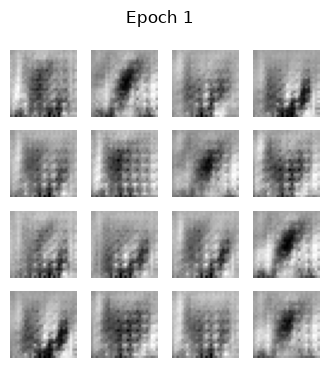

In [ ]:
def show_images(epoch):
    fake = generator(seed, training=False) # generate gambar dari noise
    plt.figure(figsize=(4, 4)) # buat figure 4x4
    for i in range(16):
        plt.subplot(4, 4, i + 1) # buat subplot 4x4
        plt.imshow(fake[i, :, :, 0] *127.5 + 127.5, cmap="gray") # ubah ke gambar awal
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

gen_losses, disc_losses = [], [] # buat list untuk nyimpen loss generator dan discriminator
for epoch in range(1, EPOCHS + 1): # loop sebanyak epoch
    g_total, d_total, n = 0,0,0
    for batch in dataset:
        g,d = train_step(batch) # train step untuk 1 batch
        g_total += float(g) # total loss generator loss
        d_total += float(d) # total loss discriminator loss
        n += 1 # n = total page
    gen_losses.append(g_total/n) # append loss generator ke list
    disc_losses.append(d_total/n) # append loss discriminator ke list

    print(f"Epoch {epoch}/{EPOCHS}, Generator Loss: {gen_losses[-1]}, Discriminator Loss: {disc_losses[-1]}")

    show_images(epoch) # show gambar hasil generate dari generator

## **Plotting**

In [ ]:
plt.plot(gen_losses, label="Generator Loss") # plot loss generator
plt.plot(disc_losses, label="Discriminator Loss") # plot loss discriminator
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()